# Proyecto Integrador de Ciencia de Datos
## Fase 2, actividad 3: Limpieza de datos e ingeniería de variables

**Universidad de La Salle**, Maestría en Inteligencia Artificial
**Asignatura:** Ciencia de Datos (2026-2). **Docente:** Fabián Camilo Castro Riveros
**Estudiante:** Martín Gracia Socha (trabajo individual)
**Conjunto de datos:** METABRIC (1.904 pacientes, 693 variables)

### Contenido
1. Configuración del entorno
2. Alcance y principio de no fuga de información
3. Limpieza determinística
4. Mecanismo de los datos faltantes (MCAR, MAR, MNAR)
5. Validez de la variable objetivo de regresión
6. Tratamiento de valores atípicos
7. Ingeniería de variables
8. Conjuntos de predictores por tarea
9. Partición estratificada de los datos
10. Selección del método de imputación (solo con entrenamiento)
11. Pipeline de preprocesamiento sin fuga
12. Artefactos generados y conclusiones

## 1. Configuración del entorno

In [1]:
import sys
import json
import warnings
from pathlib import Path

# --- Entorno: en Google Colab se clona el repositorio y se instalan dependencias faltantes ---
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/MartinGia/metabric-proyecto-integrador.git"
if IN_COLAB:
    # En Colab se clona el repositorio (datos, código y modelos) y se instalan las librerías que Colab no trae.
    import os, subprocess, importlib.util
    repo_dir = Path("/content/metabric-proyecto-integrador")
    if not (repo_dir / "src" / "config.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "notebooks")
    for pkg, module in [("imbalanced-learn", "imblearn"), ("xgboost", "xgboost"), ("shap", "shap")]:
        if importlib.util.find_spec(module) is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

def find_project_root():
    for c in [Path.cwd(), *Path.cwd().parents]:
        if (c / "src" / "config.py").exists():
            return c
    raise FileNotFoundError("No se encontró la carpeta del proyecto (debe contener src/config.py). "
                            "Abra el notebook desde la carpeta notebooks/ del repositorio.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# --- Localización de la raíz del proyecto (carpeta que contiene src/config.py) ---
# Funciona en Jupyter local, VS Code y Google Colab.
ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config
from src.cleaning import clean_metabric, npi_residual
from src.features import (add_derived_features, feature_sets, tnm_stage_rule, PROLIFERATION_GENES,
                          DRIVER_GENES, DERIVED, NEVER_PREDICTORS, NPI_LEAKAGE)
from src.preprocessing import make_splits, build_preprocessor, all_columns, Winsorizer
from src.eda_utils import missing_table, missingness_tests

config.ensure_dirs()
warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(config.RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    plt.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

print("Carpeta del proyecto:", ROOT.name)

Carpeta del proyecto: repo


## 2. Alcance y principio de no fuga de información
La guía exige tratar faltantes y atípicos con justificación, crear al menos dos variables derivadas y codificar y escalar **sin fuga de información** (*data leakage*). Para cumplirlo, las transformaciones se separan en dos tipos:

| Tipo | Ejemplos | ¿Aprende de los datos? | Cuándo se aplica |
|---|---|---|---|
| Determinística (fila por fila) | Corregir errores de digitación, deducir el grado desde la fórmula del NPI, logaritmos, puntajes génicos con listas de la literatura | No | Antes de la partición, sobre todo el conjunto |
| Aprendida | Percentiles de winsorización, modelos del IterativeImputer, medias y desviaciones del escalado, categorías del One-Hot | Sí | Dentro de un `Pipeline`, ajustado **solo con entrenamiento** |

Por esta razón, la partición entrenamiento/validación/prueba se fija en este cuaderno (sección 9), antes de ajustar cualquier transformación aprendida. La actividad 4 la reutilizará para el modelo base.

In [2]:
raw = pd.read_csv(config.RAW_FILE, low_memory=False)
clinical_cols, gene_cols, mut_cols = config.split_blocks(raw)
print(f"Datos originales: {raw.shape[0]:,} filas × {raw.shape[1]} columnas")

Datos originales: 1,904 filas × 693 columnas


## 3. Limpieza determinística
Las reglas están en `src/cleaning.py`. Cada una corrige un problema detectado en el EDA (Fase 1) y ninguna usa estadísticos del conjunto de datos.

In [3]:
df_clean, cleaning_log = clean_metabric(raw)
print(f"Datos limpios: {df_clean.shape[0]:,} filas × {df_clean.shape[1]} columnas")
with pd.option_context("display.max_colwidth", 110):
    display(cleaning_log)

Datos limpios: 1,903 filas × 692 columnas


,accion,registros_afectados,justificacion
0,Corregir 'Positve' por 'Positive',1445,Error tipográfico en la fuente.
1,Excluir el sarcoma de mama,1,No es un carcinoma; caso único fuera de la población.
2,HER2 por SNP6 'UNDEF' a faltante,4,"Es un valor indeterminado, no una categoría."
3,Estadio 0 a faltante,4,Estadio in situ incoherente con carcinomas invasivos de 11 a 65 mm.
4,mutation_count faltante a 0,45,MNAR estructural: el mínimo observado es 1 y todos los faltantes tienen 0 mutaciones en el panel.
5,Deducir el grado desde el NPI,18,"NPI = grado + estadio ganglionar + 0,002 x tamaño; el grado se despeja sin estimar nada."
6,Marcar NPI no válido (npi_valid = 0),57,El NPI se calculó sin el grado (residuo 0) o no es coherente con sus componentes.
7,Codificar cellularity como ordinal (1 a 3),1849,"Orden natural Low < Moderate < High; mapeo fijo, sin aprendizaje."
8,Mutaciones a indicadores 0/1,1903,173 columnas; el cambio de proteína no se usa en los modelos.
9,Eliminar oncotree_code,0,Redundante: mapeo uno a uno con cancer_type_detailed.


In [4]:
# Verificación de la imputación deductiva del grado: en los registros con grado observado,
# la fórmula reproduce el grado exactamente, lo que valida usarla en los faltantes.
obs = raw["neoplasm_histologic_grade"].notna() & raw["tumor_size"].notna()
resid_raw = npi_residual(raw).round(2)
acc = (resid_raw[obs] == raw.loc[obs, "neoplasm_histologic_grade"]).mean()
print(f"La fórmula reproduce el grado observado en el {100 * acc:.2f} % de {obs.sum():,} registros completos.")
print("Residuo de la fórmula en los registros SIN grado (valor = grado usado al calcular el NPI):")
display(resid_raw[raw["neoplasm_histologic_grade"].isna()].value_counts().rename("registros").to_frame().T)

La fórmula reproduce el grado observado en el 99.83 % de 1,815 registros completos.
Residuo de la fórmula en los registros SIN grado (valor = grado usado al calcular el NPI):


,0.000,1.000,2.000
registros,54,9,9


## 4. Mecanismo de los datos faltantes
La guía prohíbe imputar sin analizar el mecanismo de falta:

* **MCAR** (*Missing Completely At Random*): la ausencia no depende de ninguna variable.
* **MAR** (*Missing At Random*): la ausencia depende de variables observadas.
* **MNAR** (*Missing Not At Random*): la ausencia depende del propio valor faltante.

Para cada variable con faltantes se compara su indicador de ausencia con variables de referencia (cohorte, subtipo, receptores, edad, NPI y supervivencia) mediante χ² o Mann-Whitney U, con corrección de Bonferroni. Si alguna asociación es significativa, se descarta MCAR.

In [5]:
miss_vars = missing_table(df_clean[[c for c in clinical_cols if c in df_clean.columns]]).query("faltantes > 0")
miss_vars

,faltantes,porcentaje
tumor_stage,504,26.484
3-gene_classifier_subtype,204,10.720
primary_tumor_laterality,105,5.518
cellularity,54,2.838
neoplasm_histologic_grade,53,2.785
type_of_breast_surgery,21,1.104
tumor_size,19,0.998
tumor_other_histologic_subtype,15,0.788
cancer_type_detailed,15,0.788
her2_status_measured_by_snp6,4,0.210


Pruebas realizadas: 77; umbral de Bonferroni: α = 6.5e-04


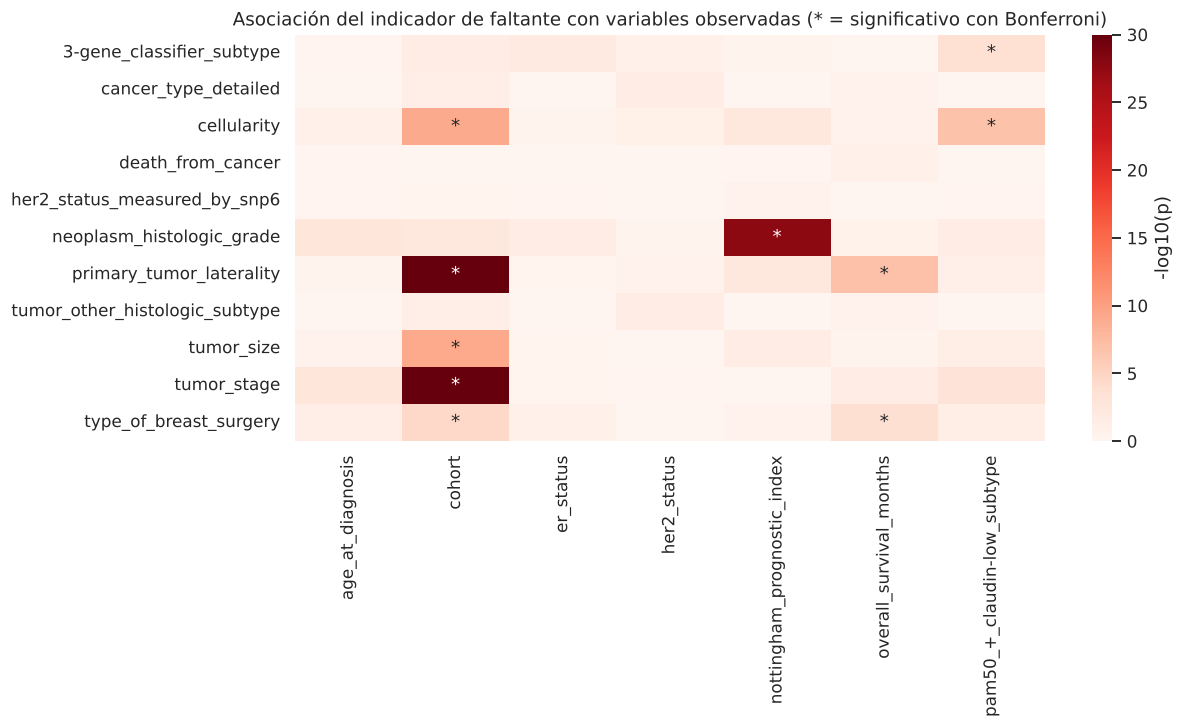

In [6]:
cat_refs = ["cohort", config.TARGET_CLASSIFICATION, "er_status", "her2_status"]
num_refs = ["age_at_diagnosis", "nottingham_prognostic_index", "overall_survival_months"]
tests = pd.concat([missingness_tests(df_clean, v, cat_refs, num_refs) for v in miss_vars.index], ignore_index=True)
alpha = 0.05 / len(tests)
tests["significativo"] = tests["p_valor"] < alpha
print(f"Pruebas realizadas: {len(tests)}; umbral de Bonferroni: α = {alpha:.1e}")

pivot = tests.pivot(index="variable", columns="referencia", values="p_valor")
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(-np.log10(pivot.clip(lower=1e-30)), annot=pivot.map(lambda p: "*" if p < alpha else ""),
            fmt="", cmap="Reds", cbar_kws={"label": "-log10(p)"}, ax=ax)
ax.set(title="Asociación del indicador de faltante con variables observadas (* = significativo con Bonferroni)",
       xlabel="", ylabel="")
savefig("12_mecanismo_faltantes")
plt.show()

In [7]:
# Proporción de faltantes por cohorte: muestra el efecto del centro de reclutamiento
by_cohort = (100 * df_clean[miss_vars.index].isna().groupby(df_clean["cohort"]).mean()).T.round(1)
by_cohort

cohort,C1,C2,C3,C4,C5
tumor_stage,4.600,0.000,14.300,100.000,84.400
3-gene_classifier_subtype,11.200,8.000,12.800,5.900,11.400
primary_tumor_laterality,3.500,2.400,0.000,34.300,0.000
cellularity,4.800,7.700,0.800,0.800,0.600
neoplasm_histologic_grade,1.900,1.000,4.500,3.000,0.600
type_of_breast_surgery,3.100,0.000,0.800,0.000,0.000
tumor_size,0.400,0.000,1.000,0.000,6.000
tumor_other_histologic_subtype,0.800,0.000,0.800,2.100,0.000
cancer_type_detailed,0.800,0.000,0.800,2.100,0.000
her2_status_measured_by_snp6,0.000,0.300,0.400,0.000,0.000


In [8]:
signif = tests[tests["significativo"]].groupby("variable")["referencia"].apply(lambda s: ", ".join(s))
decisions = {
    "tumor_stage": ("MAR", "Depende de la cohorte (100 % en C4, 84 % en C5).",
                    "Excluir de los predictores: además es redundante con tamaño y ganglios. Se crea una versión descriptiva por regla TNM."),
    "3-gene_classifier_subtype": ("MAR", "Depende del subtipo PAM50.",
                                  "Excluir: es una etiqueta derivada de la expresión génica (fuga para la clasificación)."),
    "primary_tumor_laterality": ("MAR", "Depende de la cohorte (34 % en C4).",
                                 "Excluir: sin relación biológica con los objetivos."),
    "cellularity": ("MAR", "Depende de la cohorte y del subtipo PAM50.",
                    "IterativeImputer con las demás variables clínicas, ajustado en entrenamiento (sección 10)."),
    "neoplasm_histologic_grade": ("MAR", "Depende del NPI (el NPI se calculó sin grado).",
                                  "Deducción exacta desde el NPI (18 casos) e IterativeImputer para el resto."),
    "type_of_breast_surgery": ("MAR", "Depende de la cohorte y de la supervivencia.",
                               "Excluir: es un tratamiento, no un predictor al diagnóstico."),
    "tumor_size": ("MAR", "Concentrado en la cohorte C5.",
                   "IterativeImputer sobre su logaritmo (solo predictor de clasificación)."),
    "tumor_other_histologic_subtype": ("MCAR", "Sin asociaciones significativas.",
                                       "Categoría explícita 'Desconocido' antes del One-Hot."),
    "cancer_type_detailed": ("MCAR", "Sin asociaciones significativas.",
                             "Excluir: redundante con tumor_other_histologic_subtype."),
    "her2_status_measured_by_snp6": ("MCAR", "4 valores 'UNDEF' de la medición.",
                                     "Categoría 'Desconocido' (se agrupa como poco frecuente)."),
    "death_from_cancer": ("MCAR", "Un único registro.", "Desenlace: no es predictor; se conserva sin imputar."),
}
mech = pd.DataFrame([{"variable": v, "faltantes_%": miss_vars.loc[v, "porcentaje"],
                      "asociaciones_significativas": signif.get(v, "Ninguna"),
                      "mecanismo": decisions[v][0], "evidencia": decisions[v][1], "tratamiento": decisions[v][2]}
                     for v in miss_vars.index if v in decisions]).set_index("variable")
extra = pd.DataFrame([{"variable": "mutation_count", "faltantes_%": round(100 * 45 / len(raw), 3),
                       "asociaciones_significativas": "Todos los casos tienen 0 mutaciones en el panel",
                       "mecanismo": "MNAR", "evidencia": "Falta justamente cuando el valor es 0 (mínimo observado = 1).",
                       "tratamiento": "Imputación determinística con 0 (sección 3)."}]).set_index("variable")
with pd.option_context("display.max_colwidth", 95):
    display(pd.concat([mech, extra]))

,faltantes_%,asociaciones_significativas,mecanismo,evidencia,tratamiento
variable,,,,,
tumor_stage,26.484,cohort,MAR,"Depende de la cohorte (100 % en C4, 84 % en C5).",Excluir de los predictores: además es redundante con tamaño y ganglios. Se crea una versión...
3-gene_classifier_subtype,10.720,pam50_+_claudin-low_subtype,MAR,Depende del subtipo PAM50.,Excluir: es una etiqueta derivada de la expresión génica (fuga para la clasificación).
primary_tumor_laterality,5.518,"cohort, overall_survival_months",MAR,Depende de la cohorte (34 % en C4).,Excluir: sin relación biológica con los objetivos.
cellularity,2.838,"cohort, pam50_+_claudin-low_subtype",MAR,Depende de la cohorte y del subtipo PAM50.,"IterativeImputer con las demás variables clínicas, ajustado en entrenamiento (sección 10)."
neoplasm_histologic_grade,2.785,nottingham_prognostic_index,MAR,Depende del NPI (el NPI se calculó sin grado).,Deducción exacta desde el NPI (18 casos) e IterativeImputer para el resto.
type_of_breast_surgery,1.104,"cohort, overall_survival_months",MAR,Depende de la cohorte y de la supervivencia.,"Excluir: es un tratamiento, no un predictor al diagnóstico."
tumor_size,0.998,cohort,MAR,Concentrado en la cohorte C5.,IterativeImputer sobre su logaritmo (solo predictor de clasificación).
tumor_other_histologic_subtype,0.788,Ninguna,MCAR,Sin asociaciones significativas.,Categoría explícita 'Desconocido' antes del One-Hot.
cancer_type_detailed,0.788,Ninguna,MCAR,Sin asociaciones significativas.,Excluir: redundante con tumor_other_histologic_subtype.


## 5. Validez de la variable objetivo de regresión
El EDA mostró que el NPI se calcula como grado + estadio ganglionar + 0,002 × tamaño. Al revisar los registros sin grado se encontró que, en la mayoría, el NPI **se calculó con grado igual a 0**, es decir, su valor está subestimado. Esos registros no pueden usarse como objetivo de regresión: se marcan con `npi_valid = 0` y se excluyen del entrenamiento y la evaluación del modelo de regresión (no de las demás tareas).

npi_valid
válido       1846
no válido      57


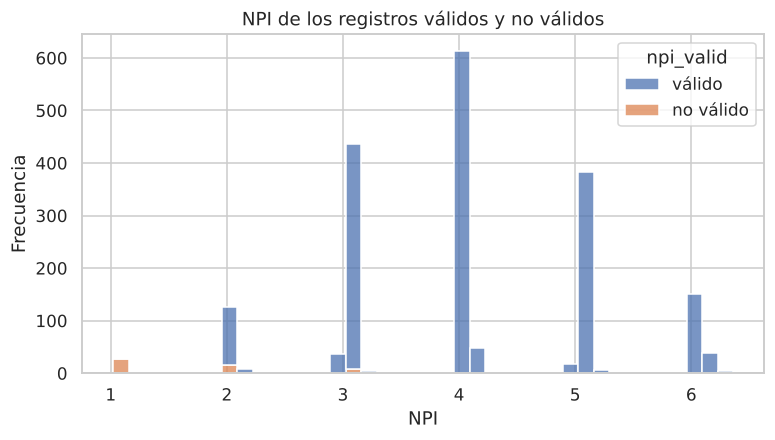

NPI medio de los registros no válidos: 1.91 | válidos: 4.1


In [9]:
print(df_clean["npi_valid"].value_counts().rename({1: "válido", 0: "no válido"}).to_string())
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df_clean, x="nottingham_prognostic_index", hue=df_clean["npi_valid"].map({1: "válido", 0: "no válido"}),
             bins=40, multiple="stack", ax=ax)
ax.set(title="NPI de los registros válidos y no válidos", xlabel="NPI", ylabel="Frecuencia")
savefig("13_npi_validez")
plt.show()
print("NPI medio de los registros no válidos:", round(df_clean.loc[df_clean.npi_valid == 0, "nottingham_prognostic_index"].mean(), 2),
      "| válidos:", round(df_clean.loc[df_clean.npi_valid == 1, "nottingham_prognostic_index"].mean(), 2))

## 6. Tratamiento de valores atípicos
Los atípicos de tamaño tumoral, ganglios positivos y número de mutaciones son **clínicamente plausibles** (no son errores), así que no se eliminan. Se aplican dos tratamientos complementarios:

1. **Transformación logarítmica** `log1p`, determinística, que reduce la asimetría.
2. **Winsorización** en los percentiles 1 y 99 dentro del pipeline (clase `Winsorizer` de `src/preprocessing.py`); los percentiles se aprenden **solo en entrenamiento**.

Los z-scores de expresión génica no se recortan: sus valores extremos pueden reflejar amplificaciones o pérdidas biológicamente relevantes.

,asimetría original,asimetría log1p,asimetría log1p + winsorización,curtosis original,curtosis log1p + winsorización
tumor_size,3.275,-0.398,0.098,20.916,0.680
lymph_nodes_examined_positive,3.838,1.176,1.133,20.720,0.334
mutation_count,4.935,-0.479,-0.618,66.117,0.794


Nota: aquí los percentiles se calculan con todo el conjunto solo para ilustrar el efecto; en el pipeline se aprenden únicamente con entrenamiento.


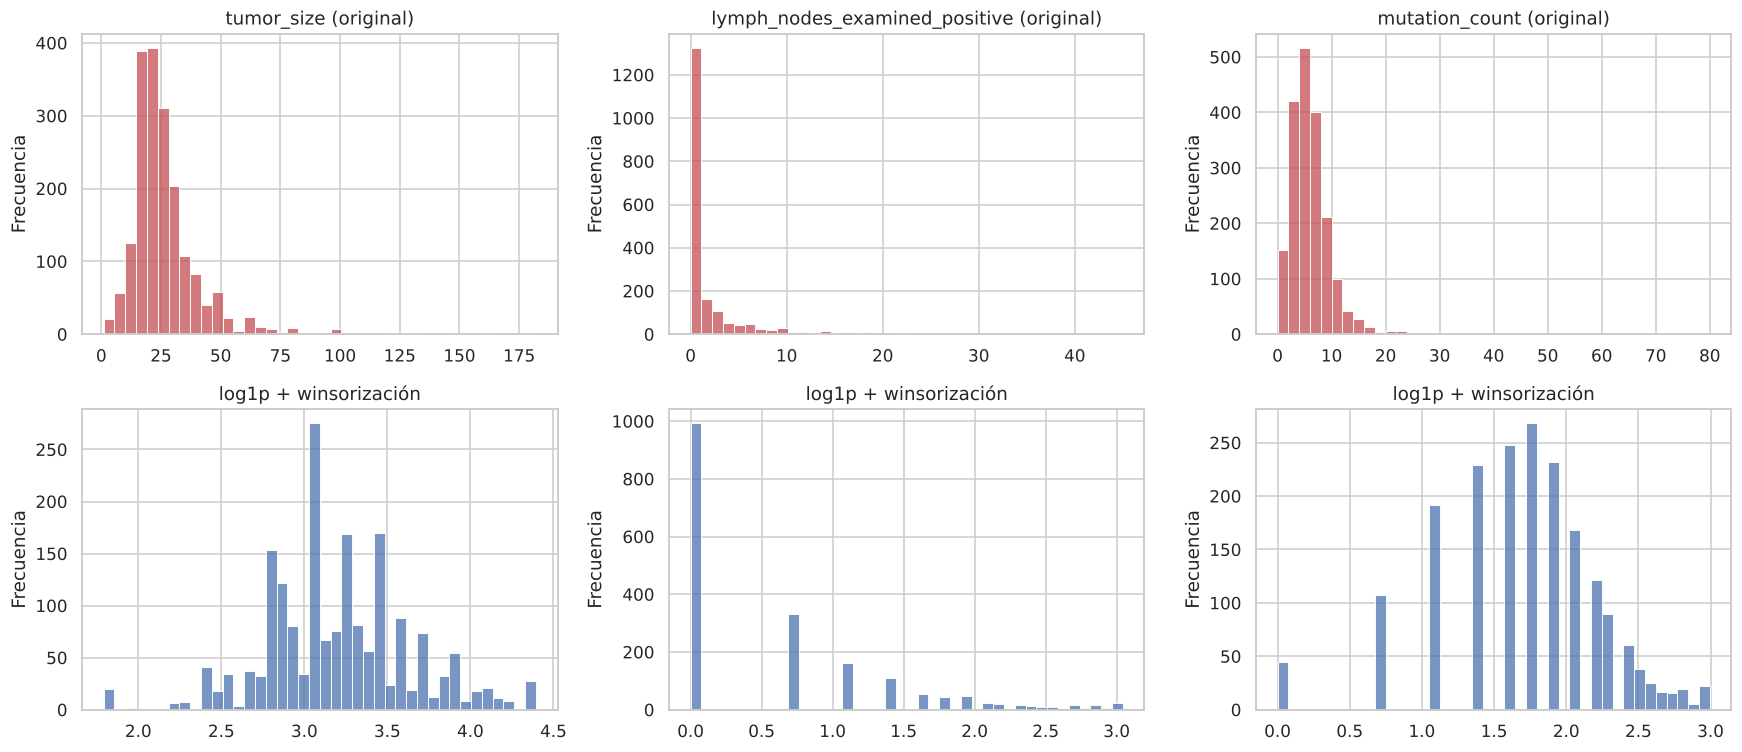

In [10]:
skew_cols = ["tumor_size", "lymph_nodes_examined_positive", "mutation_count"]
tmp = add_derived_features(df_clean)
w = Winsorizer(0.01, 0.99).fit(tmp[[f"log_{c}" for c in skew_cols]])
wins = pd.DataFrame(w.transform(tmp[[f"log_{c}" for c in skew_cols]]), columns=skew_cols)
summary = pd.DataFrame({
    "asimetría original": [tmp[c].skew() for c in skew_cols],
    "asimetría log1p": [tmp[f"log_{c}"].skew() for c in skew_cols],
    "asimetría log1p + winsorización": [wins[c].skew() for c in skew_cols],
    "curtosis original": [tmp[c].kurt() for c in skew_cols],
    "curtosis log1p + winsorización": [wins[c].kurt() for c in skew_cols],
}, index=skew_cols)
display(summary)
print("Nota: aquí los percentiles se calculan con todo el conjunto solo para ilustrar el efecto;"
      " en el pipeline se aprenden únicamente con entrenamiento.")

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for i, c in enumerate(skew_cols):
    sns.histplot(tmp[c].dropna(), bins=40, ax=axes[0, i], color="#C44E52")
    axes[0, i].set(title=f"{c} (original)", xlabel="", ylabel="Frecuencia")
    sns.histplot(wins[c].dropna(), bins=40, ax=axes[1, i], color="#4C72B0")
    axes[1, i].set(title=f"log1p + winsorización", xlabel="", ylabel="Frecuencia")
plt.tight_layout()
savefig("14_atipicos_transformacion")
plt.show()

## 7. Ingeniería de variables
Se crean variables respaldadas por conocimiento del dominio (`src/features.py`). Todas se calculan fila por fila con reglas o listas de genes tomadas de la literatura, por lo que no generan fuga.

| Variable | Definición | Justificación |
|---|---|---|
| `proliferation_score` | Promedio de los z-scores de AURKA, CCNB1, CDK1, CHEK1, CCNE1, CDC25A y E2F2 | La proliferación es el principal componente pronóstico de las firmas genómicas (Oncotype DX, Paik et al., 2004; Genomic Grade Index, Sotiriou et al., 2006) |
| `receptor_group` | HR+/HER2−, HER2+ o triple negativo, según ER, PR y HER2 | Subrogado clínico de los subtipos intrínsecos (consenso de St. Gallen; Goldhirsch et al., 2011) |
| `triple_negative` | 1 si ER−, PR− y HER2− | Grupo de peor pronóstico, cercano al subtipo Basal |
| `driver_mutation_count` | Número de genes conductores mutados (15 genes de Pereira et al., 2016) | Resume la carga de alteraciones con relevancia funcional |
| `log_tumor_size`, `log_lymph_nodes_examined_positive`, `log_mutation_count` | `log1p` de la variable original | Reduce la asimetría extrema (sección 6) |
| `node_category`, `age_group` | Categorías N0 / N1-3 / N4+ y grupos de edad | Perfiles de clústeres y filtros del dashboard |
| `tumor_stage_rule`, `tumor_stage_filled` | Estadio anatómico por regla TNM (T por tamaño, N por ganglios) | Versión completa del estadio solo para describir y filtrar |

In [11]:
df = add_derived_features(df_clean)
print(f"Variables derivadas agregadas: {len(DERIVED)} | Dimensiones: {df.shape}")
df[DERIVED].head()

Variables derivadas agregadas: 11 | Dimensiones: (1903, 703)


,proliferation_score,receptor_group,triple_negative,driver_mutation_count,log_tumor_size,log_lymph_nodes_examined_positive,log_mutation_count,node_category,age_group,tumor_stage_rule,tumor_stage_filled
0,-1.698,HR+/HER2-,0,0,3.135,2.398,0.000,N4+,>70,3.000,2.000
1,-0.482,HR+/HER2-,0,1,2.398,0.000,1.099,N0,41-50,1.000,1.000
2,0.075,HR+/HER2-,0,2,2.773,0.693,1.099,N1-3,41-50,2.000,2.000
3,0.078,HR+/HER2-,0,1,3.258,1.386,0.693,N1-3,41-50,2.000,2.000
4,0.434,HR+/HER2-,0,1,3.714,2.197,1.099,N4+,>70,3.000,2.000


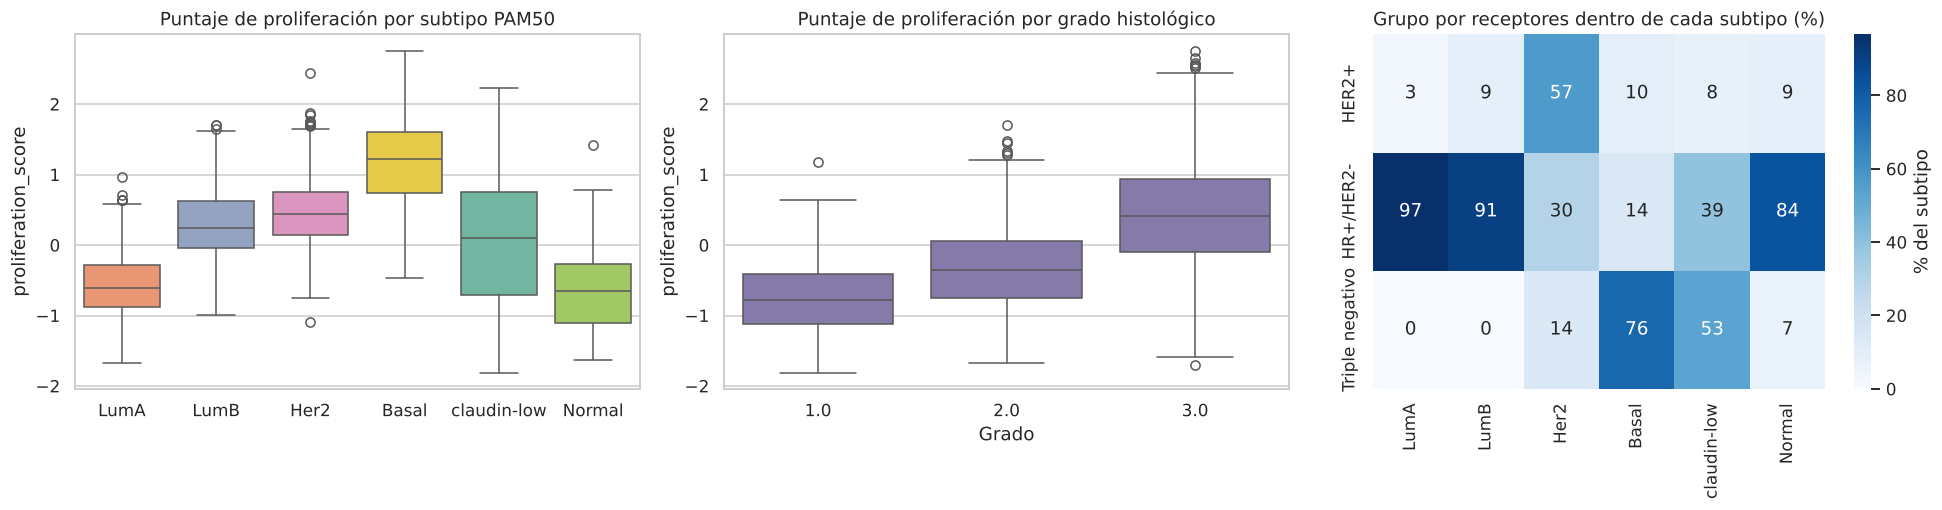

Spearman puntaje de proliferación vs. grado: 0.537
Spearman puntaje de proliferación vs. NPI válido: 0.404 (mejor gen individual del puntaje: 0.398)


In [12]:
# Validación de las variables derivadas frente a variables conocidas
order = ["LumA", "LumB", "Her2", "Basal", "claudin-low", "Normal"]
sub = df[df[config.TARGET_CLASSIFICATION] != "NC"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.boxplot(data=sub, x=config.TARGET_CLASSIFICATION, y="proliferation_score", order=order, ax=axes[0],
            hue=config.TARGET_CLASSIFICATION, palette="Set2", legend=False)
axes[0].set(title="Puntaje de proliferación por subtipo PAM50", xlabel="")
sns.boxplot(data=df, x="neoplasm_histologic_grade", y="proliferation_score", ax=axes[1], color="#8172B2")
axes[1].set(title="Puntaje de proliferación por grado histológico", xlabel="Grado")
ct = pd.crosstab(sub["receptor_group"], sub[config.TARGET_CLASSIFICATION], normalize="columns")[order] * 100
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", ax=axes[2], cbar_kws={"label": "% del subtipo"})
axes[2].set(title="Grupo por receptores dentro de cada subtipo (%)", xlabel="", ylabel="")
plt.tight_layout()
savefig("15_variables_derivadas")
plt.show()

rho_grade = stats.spearmanr(df["proliferation_score"], df["neoplasm_histologic_grade"], nan_policy="omit")[0]
rho_npi = stats.spearmanr(df.loc[df.npi_valid == 1, "proliferation_score"], df.loc[df.npi_valid == 1, "nottingham_prognostic_index"])[0]
best_gene = max(abs(stats.spearmanr(df.loc[df.npi_valid == 1, g], df.loc[df.npi_valid == 1, "nottingham_prognostic_index"])[0])
                for g in PROLIFERATION_GENES)
print(f"Spearman puntaje de proliferación vs. grado: {rho_grade:.3f}")
print(f"Spearman puntaje de proliferación vs. NPI válido: {rho_npi:.3f} (mejor gen individual del puntaje: {best_gene:.3f})")

## 8. Conjuntos de predictores por tarea
Cada tarea usa solo información disponible al momento del diagnóstico y excluye las variables que filtrarían el objetivo.

In [13]:
FS = feature_sets(df, gene_cols, mut_cols)
summary = pd.DataFrame({t: {k: len(v) for k, v in b.items()} for t, b in FS.items()}).fillna(0).astype(int)
summary.loc["total"] = summary.sum()
display(summary)

excl = pd.DataFrame([{"variable": k, "motivo": v, "aplica_a": "Todas las tareas"} for k, v in NEVER_PREDICTORS.items()] +
                    [{"variable": k, "motivo": v, "aplica_a": "Regresión (NPI)"} for k, v in NPI_LEAKAGE.items()])
with pd.option_context("display.max_colwidth", 100, "display.max_rows", 40):
    display(excl.set_index("variable"))
print("Mutaciones incluidas (prevalencia >= 2 %):", len([c for c in FS["regression"]["bin"] if c.endswith("_mut")]))

,regression,classification,clustering
num,4,7,0
ord,1,2,0
nom,7,7,0
bin,71,71,0
genes,489,489,489
total,572,576,489


,motivo,aplica_a
variable,,
patient_id,Identificador.,Todas las tareas
cohort,Lote de reclutamiento; se usa solo para analizar faltantes.,Todas las tareas
overall_survival_months,Desenlace posterior al diagnóstico.,Todas las tareas
overall_survival,Desenlace posterior al diagnóstico.,Todas las tareas
death_from_cancer,Desenlace posterior al diagnóstico.,Todas las tareas
chemotherapy,Tratamiento decidido a partir del pronóstico y el subtipo (causalidad inversa).,Todas las tareas
hormone_therapy,Tratamiento decidido a partir del pronóstico y el subtipo.,Todas las tareas
radio_therapy,Tratamiento decidido a partir del pronóstico y el subtipo.,Todas las tareas
type_of_breast_surgery,Tratamiento decidido a partir del pronóstico y el subtipo.,Todas las tareas


Mutaciones incluidas (prevalencia >= 2 %): 70


## 9. Partición estratificada de los datos
Se fija una sola partición para las tres tareas: **70 % entrenamiento, 15 % validación y 15 % prueba**, estratificada por el subtipo PAM50 y con semilla 42. Así, los tres modelos se evalúan sobre las mismas pacientes de prueba, y el dashboard puede mostrar resultados coherentes.

* **Clasificación:** se excluyen los 6 casos `NC` dentro de cada subconjunto.
* **Regresión:** se excluyen los registros con `npi_valid = 0` dentro de cada subconjunto.

In [14]:
df["split"] = make_splits(df, config.TARGET_CLASSIFICATION)
counts = pd.crosstab(df[config.TARGET_CLASSIFICATION], df["split"])[["train", "val", "test"]]
pct = (100 * counts / counts.sum()).round(1)
display(pd.concat({"n": counts, "%": pct}, axis=1))
print("Tamaños:", df["split"].value_counts()[["train", "val", "test"]].to_dict())
print("Registros por tarea y subconjunto:")
display(pd.DataFrame({
    "regresión (npi_valid = 1)": df[df.npi_valid == 1]["split"].value_counts(),
    "clasificación (sin NC)": df[df[config.TARGET_CLASSIFICATION] != "NC"]["split"].value_counts(),
    "clustering": df["split"].value_counts(),
}).loc[["train", "val", "test"]])
# Prueba chi-cuadrado: la distribución del subtipo no difiere entre subconjuntos
print("Chi² subtipo vs. subconjunto: p = %.3f" % stats.chi2_contingency(counts)[1])

n                %              
split                       train  val test  train    val   test
pam50_+_claudin-low_subtype                                     
Basal                         139   30   30 10.400 10.500 10.500
Her2                          154   33   33 11.600 11.600 11.500
LumA                          475  102  102 35.700 35.800 35.700
LumB                          323   69   69 24.200 24.200 24.100
NC                              4    1    1  0.300  0.400  0.300
Normal                         98   21   21  7.400  7.400  7.300
claudin-low                   139   29   30 10.400 10.200 10.500

Tamaños: {'train': 1332, 'val': 285, 'test': 286}
Registros por tarea y subconjunto:


,regresión (npi_valid = 1),clasificación (sin NC),clustering
split,,,
train,1285,1328,1332
val,280,284,285
test,281,285,286


Chi² subtipo vs. subconjunto: p = 1.000


## 10. Selección del método de imputación (solo con entrenamiento)
Para elegir con evidencia cómo imputar el grado histológico y la celularidad (MAR), se hace un experimento de **enmascaramiento** dentro del conjunto de entrenamiento: se ocultan al azar el 15 % de los valores observados, se imputan con cada método y se compara la exactitud al redondear al nivel ordinal más cercano. Se repite 20 veces con semillas distintas. Validación y prueba no se tocan.

exactitud         MAE      
                                                       mean   std  mean   std
variable                  método                                             
cellularity_ord           IterativeImputer            0.490 0.035 0.566 0.020
                          KNNImputer (k = 5)          0.483 0.029 0.577 0.029
                          Mediana (SimpleImputer)     0.396 0.033 0.604 0.033
                          Moda (SimpleImputer)        0.497 0.034 0.609 0.045
neoplasm_histologic_grade IterativeImputer            0.978 0.010 0.168 0.006
                          KNNImputer (k = 5)          0.871 0.016 0.180 0.013
                          Mediana (SimpleImputer)     0.500 0.029 0.592 0.041
                          Moda (SimpleImputer)        0.500 0.029 0.592 0.041

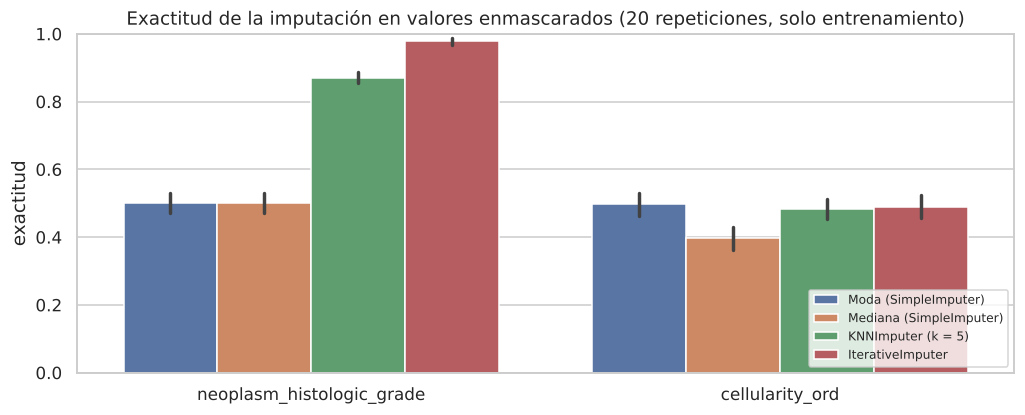

In [15]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler

train = df[df["split"] == "train"]
ctx = ["age_at_diagnosis", "log_tumor_size", "log_lymph_nodes_examined_positive", "nottingham_prognostic_index",
       "proliferation_score", "log_mutation_count"]
targets = ["neoplasm_histologic_grade", "cellularity_ord"]
X0 = train[ctx + targets].copy()

methods = {
    "Moda (SimpleImputer)": lambda: SimpleImputer(strategy="most_frequent"),
    "Mediana (SimpleImputer)": lambda: SimpleImputer(strategy="median"),
    "KNNImputer (k = 5)": lambda: KNNImputer(n_neighbors=5),
    "IterativeImputer": lambda: IterativeImputer(max_iter=20, random_state=0),
}
rows = []
for rep in range(20):
    rng = np.random.default_rng(rep)
    Xm = X0.copy()
    masks = {}
    for t in targets:
        obs_idx = np.flatnonzero(X0[t].notna())
        hide = rng.choice(obs_idx, size=int(0.15 * len(obs_idx)), replace=False)
        masks[t] = hide
        Xm.iloc[hide, Xm.columns.get_loc(t)] = np.nan
    scaler = StandardScaler().fit(Xm)
    Xs = scaler.transform(Xm)
    for name, make in methods.items():
        imp = scaler.inverse_transform(make().fit_transform(Xs))
        for t in targets:
            j = Xm.columns.get_loc(t)
            pred = np.clip(np.round(imp[masks[t], j]), 1, 3)
            true = X0[t].to_numpy()[masks[t]]
            rows.append({"método": name, "variable": t, "rep": rep,
                         "exactitud": (pred == true).mean(), "MAE": np.abs(imp[masks[t], j] - true).mean()})
res = pd.DataFrame(rows)
imp_summary = res.groupby(["variable", "método"])[["exactitud", "MAE"]].agg(["mean", "std"]).round(3)
display(imp_summary)

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=res, x="variable", y="exactitud", hue="método", errorbar="sd", ax=ax)
ax.set(title="Exactitud de la imputación en valores enmascarados (20 repeticiones, solo entrenamiento)",
       xlabel="", ylim=(0, 1))
ax.legend(fontsize=8, loc="lower right")
savefig("16_experimento_imputacion")
plt.show()

In [16]:
# Estadio tumoral: ¿qué tan bien lo reproduce la regla TNM frente a la moda? (solo entrenamiento)
tr = train[train["tumor_stage"].notna() & train["tumor_stage_rule"].notna()]
mode_stage = tr["tumor_stage"].mode()[0]
print(f"Exactitud de la regla TNM: {100 * (tr['tumor_stage_rule'] == tr['tumor_stage']).mean():.1f} % | "
      f"Exactitud de la moda ({mode_stage:.0f}): {100 * (tr['tumor_stage'] == mode_stage).mean():.1f} %")

Exactitud de la regla TNM: 82.9 % | Exactitud de la moda (2): 57.3 %


## 11. Pipeline de preprocesamiento sin fuga
El `ColumnTransformer` de `src/preprocessing.py` agrupa todas las transformaciones aprendidas:

* **Clínicas cuantitativas y ordinales:** winsorización 1-99 % → `StandardScaler` → `IterativeImputer` (elegido en la sección 10).
* **Nominales:** imputación con la categoría `Desconocido` → One-Hot (`handle_unknown`, categorías con menos de 10 casos agrupadas).
* **Expresión génica:** `StandardScaler`.
* **Mutaciones e indicadores binarios:** sin cambios.

Se ajusta **solo con entrenamiento** y se aplica a validación y prueba. La verificación final comprueba que las medias de entrenamiento quedan en 0 y las de validación y prueba no exactamente en 0, señal de que sus estadísticos no se usaron en el ajuste.

In [17]:
check_rows = []
for task in ["regression", "classification"]:
    blocks = FS[task]
    cols = all_columns(blocks)
    if task == "regression":
        mask = df["npi_valid"] == 1
    else:
        mask = df[config.TARGET_CLASSIFICATION] != "NC"
    d = df[mask]
    pre = build_preprocessor(blocks)
    Xtr = pre.fit_transform(d[d.split == "train"][cols])           # fit SOLO en entrenamiento
    Xva = pre.transform(d[d.split == "val"][cols])                  # solo transform
    Xte = pre.transform(d[d.split == "test"][cols])
    names = pre.get_feature_names_out()
    g = [i for i, n in enumerate(names) if n.startswith("genes__")]
    check_rows.append({
        "tarea": task, "predictores_originales": len(cols), "columnas_tras_preprocesar": Xtr.shape[1],
        "n_train": Xtr.shape[0], "n_val": Xva.shape[0], "n_test": Xte.shape[0],
        "NaN_restantes": int(np.isnan(Xtr).sum() + np.isnan(Xva).sum() + np.isnan(Xte).sum()),
        "media_genes_train": Xtr[:, g].mean(), "media_genes_val": Xva[:, g].mean(), "media_genes_test": Xte[:, g].mean(),
    })
display(pd.DataFrame(check_rows).set_index("tarea"))
print("Bloques del preprocesador de clasificación:")
for name, trans, cols in pre.transformers_:
    print(f"  {name:<9} {len(cols):>4} columnas -> {trans if isinstance(trans, str) else type(trans).__name__}")

,predictores_originales,columnas_tras_preprocesar,n_train,n_val,n_test,NaN_restantes,media_genes_train,media_genes_val,media_genes_test
tarea,,,,,,,,,
regression,572,588,1285,280,281,0,0.000,0.001,0.008
classification,576,593,1328,284,285,0,0.000,0.001,0.008


Bloques del preprocesador de clasificación:
  clinical     9 columnas -> Pipeline
  nominal      7 columnas -> Pipeline
  genes      489 columnas -> StandardScaler
  binary      71 columnas -> FunctionTransformer


## 12. Artefactos generados y conclusiones

In [18]:
out_clean = config.DATA_PROCESSED / "metabric_clean.csv"
df.to_csv(out_clean, index=False)
df[["patient_id", "split"]].to_csv(config.DATA_PROCESSED / "splits.csv", index=False)
with open(config.DATA_PROCESSED / "feature_sets.json", "w", encoding="utf-8") as f:
    json.dump(FS, f, ensure_ascii=False, indent=1)
cleaning_log.to_csv(config.DOCS_DIR / "bitacora_limpieza.csv", index=False, encoding="utf-8-sig")
for p in [out_clean, config.DATA_PROCESSED / "splits.csv", config.DATA_PROCESSED / "feature_sets.json",
          config.DOCS_DIR / "bitacora_limpieza.csv"]:
    print(f"{p.relative_to(config.ROOT_DIR)}  ({p.stat().st_size / 1024:,.0f} KB)")

data/processed/metabric_clean.csv  (8,139 KB)
data/processed/splits.csv  (19 KB)
data/processed/feature_sets.json  (20 KB)
docs/bitacora_limpieza.csv  (1 KB)


### Conclusiones de la actividad 3

1. **Limpieza.** Se aplicaron 12 reglas determinísticas: se corrigieron 1.445 categorías mal escritas, se excluyó el único sarcoma (quedan 1.903 pacientes), los valores indeterminados (`UNDEF`) y los estadios 0 incoherentes pasaron a faltantes, y se eliminaron tres columnas redundantes o constantes.
2. **Mecanismo de los faltantes.** De las 12 variables con faltantes, 7 son **MAR** (dependen sobre todo de la cohorte de reclutamiento, del subtipo o del NPI), 4 son compatibles con **MCAR** y una es **MNAR estructural**: `mutation_count` falta exactamente cuando el tumor no tiene mutaciones en el panel, por lo que se imputó con 0. Ninguna imputación se hizo sin esta justificación.
3. **Imputación deductiva y validez del objetivo.** La fórmula del NPI reproduce el grado observado en el 99,8 % de los casos, lo que permitió recuperar 18 grados sin estimar nada. También reveló que 57 registros tienen un NPI calculado sin grado o incoherente (media 1,9 frente a 4,1); se excluyen del modelo de regresión.
4. **Atípicos.** Se conservaron por ser clínicamente plausibles. La combinación de `log1p` y winsorización (1-99 %, aprendida en entrenamiento) reduce la asimetría del tamaño tumoral de 3,3 a 0,1 y la del número de mutaciones de 4,9 a −0,6.
5. **Variables derivadas.** Se crearon 11, cuatro de ellas con respaldo directo de la literatura: puntaje de proliferación, grupo por receptores, indicador triple negativo y carga de mutaciones conductoras. El puntaje de proliferación se correlaciona con el grado (ρ = 0,54) y con el NPI válido (ρ = 0,40), con más estabilidad que un gen aislado. El grupo por receptores coincide con la biología: el 96,6 % de los Luminal A son HR+/HER2− y el 75,9 % de los Basal son triple negativos.
6. **Prevención de fuga.** Se excluyeron desenlaces, tratamientos, etiquetas derivadas de la expresión y, para la regresión, los componentes del NPI. Todas las transformaciones aprendidas están en un `ColumnTransformer` ajustado solo con entrenamiento; las medias de los genes son 0 en entrenamiento y distintas de 0 en validación y prueba.
7. **Partición.** 1.332 / 285 / 286 pacientes (70/15/15), estratificada por PAM50; la distribución del subtipo es la misma en los tres subconjuntos (χ², p = 1,00).
8. **Imputación elegida con evidencia.** En el experimento de enmascaramiento, IterativeImputer recupera el grado con 97,8 % de exactitud, frente a 87,1 % de KNNImputer y 50 % de la moda. Para la celularidad todos los métodos rondan el 50 % (la variable aporta poca información), y se mantiene IterativeImputer por tener el menor error absoluto.

**Siguiente paso (actividad 4):** cargar `splits.csv` y `feature_sets.json`, construir los modelos base (regresión lineal simple y `DummyRegressor` para el NPI; `DummyClassifier` y regresión logística para PAM50) dentro de un `Pipeline` con este preprocesador y fijar el umbral mínimo de desempeño.